In [1]:
from setup_ipynb_paths import setup_project_root
PROJECT_ROOT = setup_project_root()
data_path = PROJECT_ROOT / "data"

import scripts.evaluation_utils as eval_utils
import scripts.desom as desom
import scripts.som as som
import scripts.ae_and_som as ae_som

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [2]:

def show_examples(X, y, n=10):
    plt.figure(figsize=(12, 2))

    for i in range(n):
        plt.subplot(1, n, i + 1)
        plt.imshow(X[i].reshape(28, 28), cmap="gray")
        plt.title(str(y[i]))
        plt.axis("off")

    plt.show()

def show_fashion_examples(X, y, n=10):
    fashion_labels = {
    0: "T-shirt/top",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle boot"
    }

    plt.figure(figsize=(14, 2))

    for i in range(n):
        plt.subplot(1, n, i + 1)
        plt.imshow(X[i].reshape(28, 28), cmap="gray")
        plt.title(fashion_labels[y[i]], fontsize=8)
        plt.axis("off")

    plt.show()

## **Chargement d'une partie de MNIST**

In [3]:
X_train, y_train, X_test, y_test = eval_utils.load_dataset(name="MNIST", root=data_path, n_train=10000, n_test=2000)
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(10000, 784)
(10000,)
(2000, 784)
(2000,)


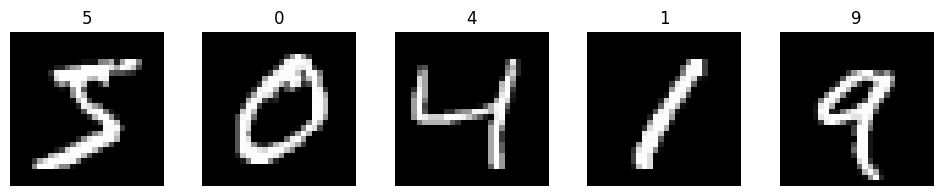

In [4]:
show_examples(X_train, y_train, n=5)

In [5]:
grid_size = (10, 10)
save_path = PROJECT_ROOT / "rapport/images"

## **Pour Batch SOM**

In [6]:
batch_som = som.batchSOM(rayon_init=8.0, grid_size=grid_size, n_steps=250, dis_choice="euclidean", calculate_qe=True)
weights_som, history_som = batch_som.train(X_train)

results_som = eval_utils.evaluate_som_model(
    model_name="SOM",
    data=X_test,
    weights=weights_som,
    y_true=y_test,
    grid_size=grid_size,
    training_time=None
)
results_som

{'Modèle': 'SOM',
 'QE': np.float64(5.2659654235293285),
 'TE': 0.436,
 'Pureté': np.float64(0.7935),
 'NMI': 0.5286083406254362,
 'Grille': '10x10'}

## **Pour AE + Batch SOM**

In [7]:
ae_som_model = ae_som.AESOM(
    input_dim=784,
    latent_dim=10,
    rayon_init=8.0,
    grid_size=grid_size,
    n_steps_som=250, 
    weight_init="random",
    dis_choice="euclidean",
    topology="rectangular"
)

ae_losses, weights_ae_som = ae_som_model.train_ae_n_som(X_train)

Z_test = ae_som_model.encode_latent(X_test)

weights_ae_som, _ = weights_ae_som

results_ae_som = eval_utils.evaluate_som_model(
    model_name="AE+SOM",
    data=Z_test,
    weights=weights_ae_som,
    y_true=y_test,
    grid_size=grid_size,
    training_time=None
)
results_ae_som
    

{'Modèle': 'AE+SOM',
 'QE': np.float64(1.2964327469575656),
 'TE': 0.473,
 'Pureté': np.float64(0.834),
 'NMI': 0.542574867889483,
 'Grille': '10x10'}

## **Pour DESOM**

In [8]:
Desom_model = desom.DESOM(
    grid_size=grid_size,
    input_dim=784,
    latent_dim=10,
    gamma=1e-3
)

desom_losses = Desom_model.embedded_train(X_train, sigma_init=8.0)

Z_test_desom = Desom_model.encode(X_test).detach().cpu().numpy()

weights_desom = Desom_model.som.weights.detach().cpu().numpy()

results_desom = eval_utils.evaluate_som_model(
    model_name="DESOM",
    data=Z_test_desom,
    weights=weights_desom,
    y_true=y_test,
    grid_size=grid_size,
    training_time=None
)
results_desom

{'Modèle': 'DESOM',
 'QE': np.float64(0.2473424196862),
 'TE': 0.6045,
 'Pureté': np.float64(0.843),
 'NMI': 0.5534242234199119,
 'Grille': '10x10'}

## **Creation de tableau**

In [9]:

list_results = [results_som, results_ae_som, results_desom]
df_results = eval_utils.create_results_dataframe_to_latex(list_results)

## **U-matrices**

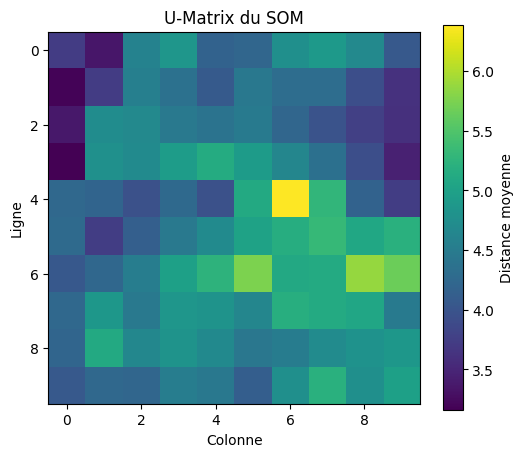

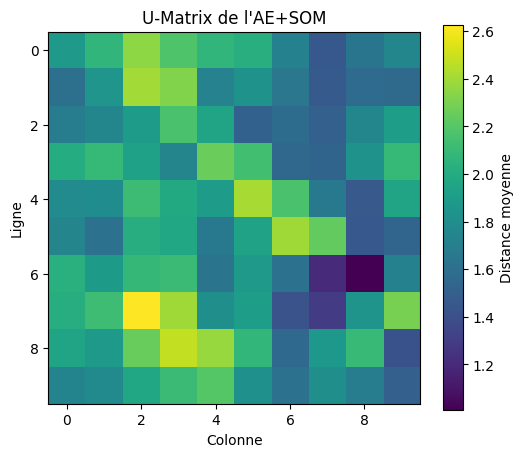

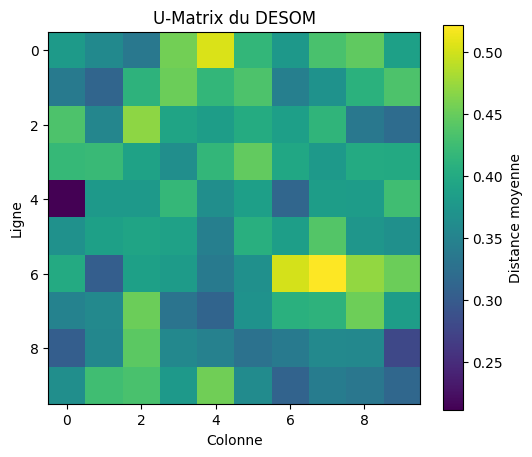

In [10]:
# batch SOM
eval_utils.plot_u_matrix(weights_som, grid_size, title="U-Matrix du SOM", save_path=save_path / "u_matrix_som.png")

# AE+SOM
eval_utils.plot_u_matrix(weights_ae_som, grid_size, title="U-Matrix de l'AE+SOM", save_path=save_path / "u_matrix_ae_som.png")

# DESOM
eval_utils.plot_u_matrix(weights_desom, grid_size, title="U-Matrix du DESOM", save_path=save_path / "u_matrix_desom.png")


# **Label maps**

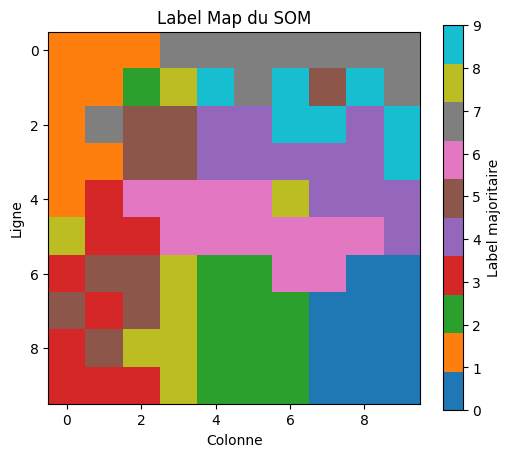

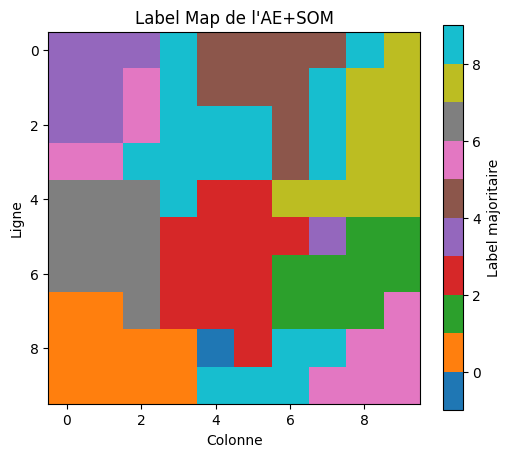

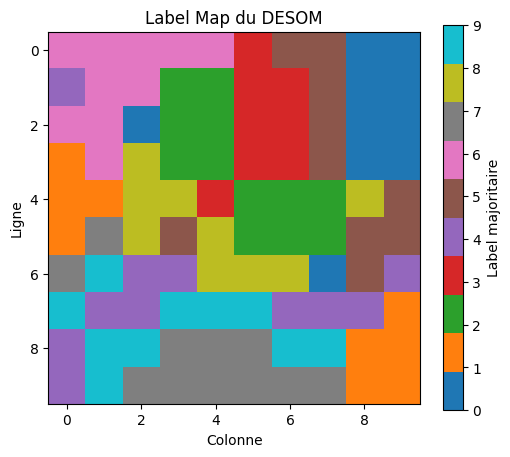

In [11]:
# batch SOM
eval_utils.plot_label_map(X_test,weights_som, y_test, grid_size, title="Label Map du SOM", save_path=save_path / "label_map_som.png")

# AE+SOM
eval_utils.plot_label_map(Z_test,weights_ae_som, y_test, grid_size, title="Label Map de l'AE+SOM", save_path=save_path / "label_map_ae_som.png")

# DESOM
eval_utils.plot_label_map(Z_test_desom, weights_desom, y_test, grid_size, title="Label Map du DESOM", save_path=save_path / "label_map_desom.png")

# **Hit maps**

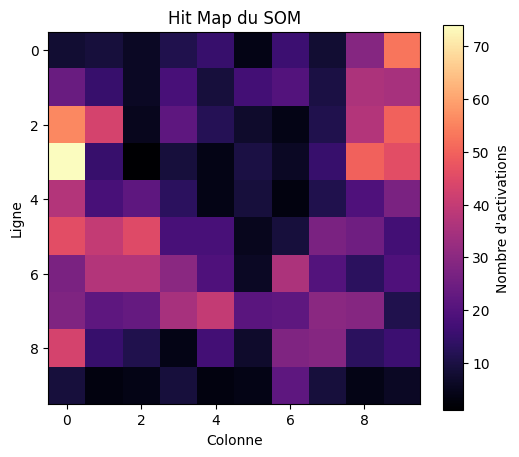

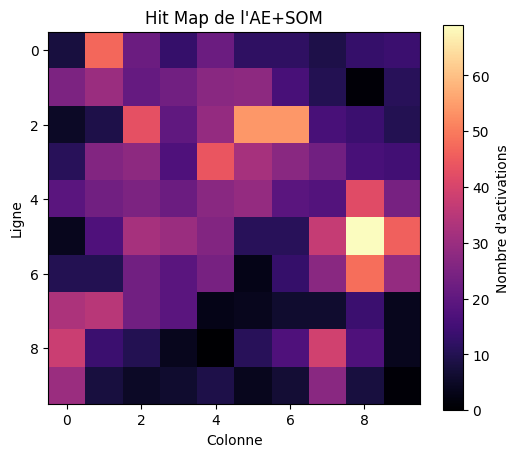

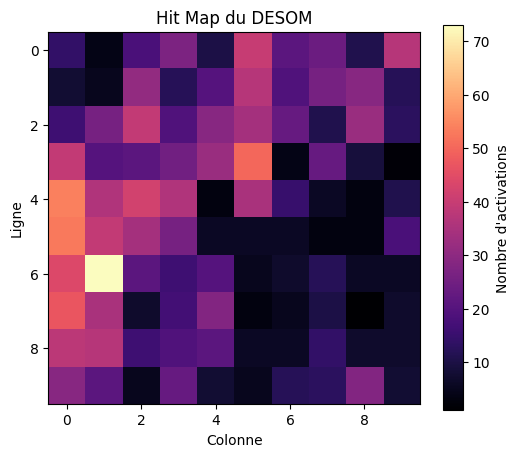

In [12]:
# batch SOM
eval_utils.hit_map(X_test, weights_som, grid_size, title="Hit Map du SOM", save_path=save_path / "hit_map_som.png")

# AE+SOM
eval_utils.hit_map(Z_test, weights_ae_som, grid_size, title="Hit Map de l'AE+SOM", save_path=save_path / "hit_map_ae_som.png")

# DESOM
eval_utils.hit_map(Z_test_desom, weights_desom, grid_size, title="Hit Map du DESOM", save_path=save_path / "hit_map_desom.png")

## **Courbe d'apprentissage**

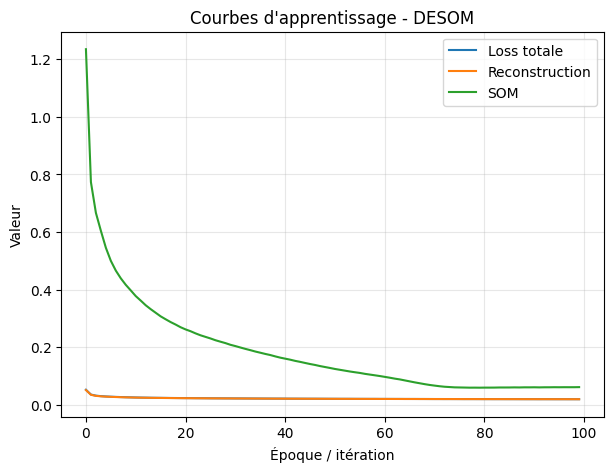

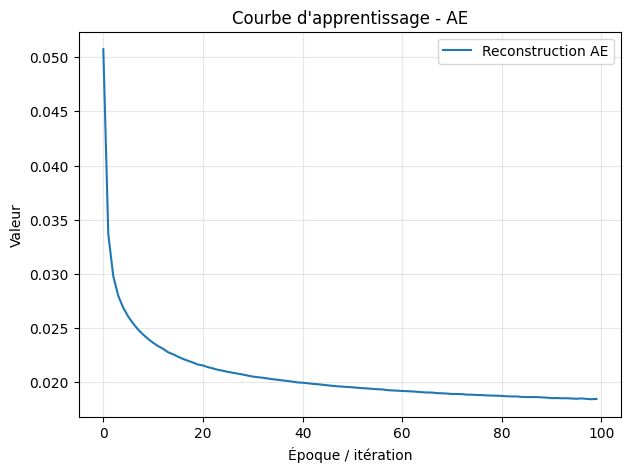

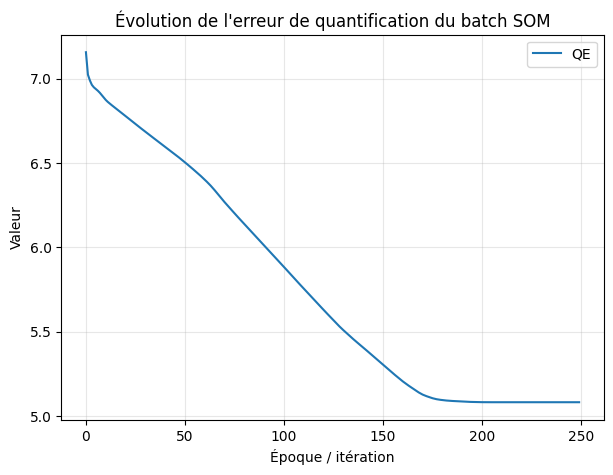

In [13]:
# DESOM
eval_utils.plot_training_curves(
    {
        "Loss totale": desom_losses["total"],
        "Reconstruction": desom_losses["reconstruction"],
        "SOM": desom_losses["som"],
    },
    title="Courbes d'apprentissage - DESOM",
    save_path=save_path / "training_curves_desom.png"
)

# AE+SOM
eval_utils.plot_training_curves(
    {
        "Reconstruction AE": ae_losses
    },
    title="Courbe d'apprentissage - AE",
    save_path=save_path / "training_curves_ae.png"
)

# batch SOM n'a pas de courbe d'apprentissage à proprement parler, mais on peut visualiser 
# l'évolution de la quantization error
eval_utils.plot_training_curves(history_som, title="Évolution de l'erreur de quantification du batch SOM", 
                                save_path=save_path / "training_curves_som.png")


## **Etude de la taille de grille** 

In [19]:
results = []

for gs in [(6, 6),(8, 8),(10, 10),(12, 12),(15, 15)]:
    
    rayon_init = max(gs) / 2

    # =========================
    # batch SOM
    # =========================
    batch_som = som.batchSOM(
        rayon_init= rayon_init, 
        grid_size=gs, 
        n_steps=250, 
        dis_choice="euclidean" 
    )

    weights_som, history_som = batch_som.train(X_train)

    results_som = eval_utils.evaluate_som_model(
        model_name="SOM",
        data=X_test,
        weights=weights_som,
        y_true=y_test,
        grid_size=gs,
        training_time=None
    )
    results.append(results_som)

    # =========================
    # AE+SOM
    # =========================
    ae_som_model = ae_som.AESOM(
        input_dim=784,
        latent_dim=10,
        rayon_init= rayon_init,
        grid_size=gs,
        n_steps_som=250, 
        weight_init="random",
        dis_choice="euclidean",
        topology="rectangular"
    )
    ae_losses, weights_ae_som = ae_som_model.train_ae_n_som(X_train)

    Z_test = ae_som_model.encode_latent(X_test)
    weights_ae_som, _ = weights_ae_som # on ne garde que les poids finaux du SOM pas l'historique

    results_ae_som = eval_utils.evaluate_som_model(
        model_name="AE+SOM",
        data=Z_test,
        weights=weights_ae_som,
        y_true=y_test,
        grid_size=gs,
        training_time=None
    )
    results.append(results_ae_som)

    # =========================
    # DESOM
    # =========================
    Desom_model = desom.DESOM(
    grid_size=gs,
    input_dim=784,
    latent_dim=10,
    gamma=1e-3
    )

    desom_losses = Desom_model.embedded_train(X_train, sigma_init= rayon_init)

    Z_test_desom = Desom_model.encode(X_test).detach().cpu().numpy()

    weights_desom = Desom_model.som.weights.detach().cpu().numpy()

    results_desom = eval_utils.evaluate_som_model(
        model_name="DESOM",
        data=Z_test_desom,
        weights=weights_desom,
        y_true=y_test,
        grid_size=gs,
        training_time=None
    )
    results.append(results_desom)
    

df_results = pd.DataFrame(results)
df_results["n_noeuds"] = df_results["Grille"].apply(
    lambda s: int(s.split("x")[0]) * int(s.split("x")[1])
)

df_results.to_latex("grid_size_study_results.tex", index=False)

eval_utils.plot_grid_size_study(df_results, metric="QE", title="Impact de la taille de la grille sur le QE")
eval_utils.plot_grid_size_study(df_results, metric="TE", title="Impact de la taille de la grille sur le TE")
eval_utils.plot_grid_size_study(df_results, metric="Pureté", title="Impact de la taille de la grille sur la pureté")
eval_utils.plot_grid_size_study(df_results, metric="NMI", title="Impact de la taille de la grille sur le NMI")



: 

## **Chargement d'une partie de Fashion-MNIST**

In [15]:
X_train_fashion, y_train_fashion, X_test_fashion, y_test_fashion = eval_utils.load_dataset(name="FashionMNIST", root=data_path, n_train=10000, n_test=2000)
print(X_train_fashion.shape)
print(y_train_fashion.shape)
print(X_test_fashion.shape)
print(y_test_fashion.shape)

(10000, 784)
(10000,)
(2000, 784)
(2000,)


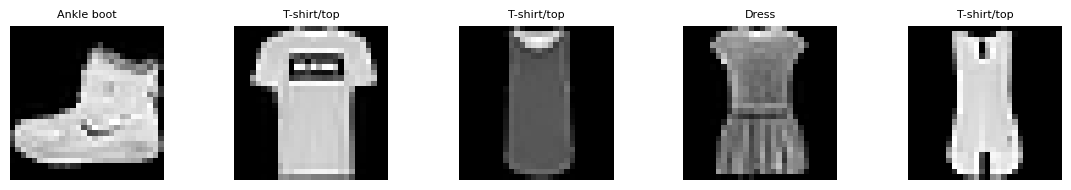

In [16]:
show_fashion_examples(X_train_fashion, y_train_fashion, n=5)

## **Fashion-MNIST - Paramètres**

In [17]:
grid_size_fashion = (10, 10)
save_path_fashion = PROJECT_ROOT / "rapport/images"

## **Fashion-MNIST - Pour Batch SOM**

In [ ]:
batch_som_fashion = som.batchSOM(rayon_init=8.0, grid_size=grid_size_fashion, n_steps=250, dis_choice="euclidean", calculate_qe=True)
weights_som_fashion, history_som_fashion = batch_som_fashion.train(X_train_fashion)

results_som_fashion = eval_utils.evaluate_som_model(
    model_name="SOM",
    data=X_test_fashion,
    weights=weights_som_fashion,
    y_true=y_test_fashion,
    grid_size=grid_size_fashion,
    training_time=None
)
results_som_fashion

## **Fashion-MNIST - Pour AE + Batch SOM**

In [ ]:
ae_som_model_fashion = ae_som.AESOM(
    input_dim=784,
    latent_dim=10,
    rayon_init=8.0,
    grid_size=grid_size_fashion,
    n_steps_som=250, 
    weight_init="random",
    dis_choice="euclidean",
    topology="rectangular"
)

ae_losses_fashion, weights_ae_som_fashion = ae_som_model_fashion.train_ae_n_som(X_train_fashion)

Z_test_fashion = ae_som_model_fashion.encode_latent(X_test_fashion)

weights_ae_som_fashion, _ = weights_ae_som_fashion

results_ae_som_fashion = eval_utils.evaluate_som_model(
    model_name="AE+SOM",
    data=Z_test_fashion,
    weights=weights_ae_som_fashion,
    y_true=y_test_fashion,
    grid_size=grid_size_fashion,
    training_time=None
)
results_ae_som_fashion

## **Fashion-MNIST - Pour DESOM**

In [ ]:
desom_model_fashion = desom.DESOM(
    grid_size=grid_size_fashion,
    input_dim=784,
    latent_dim=10,
    gamma=1e-3
)

desom_losses_fashion = desom_model_fashion.embedded_train(X_train_fashion, sigma_init=8.0)

Z_test_desom_fashion = desom_model_fashion.encode(X_test_fashion).detach().cpu().numpy()

weights_desom_fashion = desom_model_fashion.som.weights.detach().cpu().numpy()

results_desom_fashion = eval_utils.evaluate_som_model(
    model_name="DESOM",
    data=Z_test_desom_fashion,
    weights=weights_desom_fashion,
    y_true=y_test_fashion,
    grid_size=grid_size_fashion,
    training_time=None
)
results_desom_fashion

## **Fashion-MNIST - Création de tableau**

In [ ]:
list_results_fashion = [results_som_fashion, results_ae_som_fashion, results_desom_fashion]
df_results_fashion = eval_utils.create_results_dataframe_to_latex(list_results_fashion)
df_results_fashion
df_results_fashion.to_latex(PROJECT_ROOT / "notebooks/resultats_des_metriques_fashion.tex", index=False)

## **Fashion-MNIST - U-matrices**

In [ ]:
# batch SOM
eval_utils.plot_u_matrix(weights_som_fashion, grid_size_fashion, title="U-Matrix du SOM - Fashion-MNIST", save_path=save_path_fashion / "u_matrix_som_fashion.png")

# AE+SOM
eval_utils.plot_u_matrix(weights_ae_som_fashion, grid_size_fashion, title="U-Matrix de l'AE+SOM - Fashion-MNIST", save_path=save_path_fashion / "u_matrix_ae_som_fashion.png")

# DESOM
eval_utils.plot_u_matrix(weights_desom_fashion, grid_size_fashion, title="U-Matrix du DESOM - Fashion-MNIST", save_path=save_path_fashion / "u_matrix_desom_fashion.png")

## **Fashion-MNIST - Label maps**

In [ ]:
# batch SOM
eval_utils.plot_label_map(X_test_fashion, weights_som_fashion, y_test_fashion, grid_size_fashion, title="Label Map du SOM - Fashion-MNIST", save_path=save_path_fashion / "label_map_som_fashion.png")

# AE+SOM
eval_utils.plot_label_map(Z_test_fashion, weights_ae_som_fashion, y_test_fashion, grid_size_fashion, title="Label Map de l'AE+SOM - Fashion-MNIST", save_path=save_path_fashion / "label_map_ae_som_fashion.png")

# DESOM
eval_utils.plot_label_map(Z_test_desom_fashion, weights_desom_fashion, y_test_fashion, grid_size_fashion, title="Label Map du DESOM - Fashion-MNIST", save_path=save_path_fashion / "label_map_desom_fashion.png")

## **Fashion-MNIST - Hit maps**

In [ ]:
# batch SOM
eval_utils.hit_map(X_test_fashion, weights_som_fashion, grid_size_fashion, title="Hit Map du SOM - Fashion-MNIST", save_path=save_path_fashion / "hit_map_som_fashion.png")

# AE+SOM
eval_utils.hit_map(Z_test_fashion, weights_ae_som_fashion, grid_size_fashion, title="Hit Map de l'AE+SOM - Fashion-MNIST", save_path=save_path_fashion / "hit_map_ae_som_fashion.png")

# DESOM
eval_utils.hit_map(Z_test_desom_fashion, weights_desom_fashion, grid_size_fashion, title="Hit Map du DESOM - Fashion-MNIST", save_path=save_path_fashion / "hit_map_desom_fashion.png")

## **Fashion-MNIST - Courbes d'apprentissage**

In [ ]:
# DESOM
eval_utils.plot_training_curves(
    {
        "Loss totale": desom_losses_fashion["total"],
        "Reconstruction": desom_losses_fashion["reconstruction"],
        "SOM": desom_losses_fashion["som"],
    },
    title="Courbes d'apprentissage - DESOM (Fashion-MNIST)",
    save_path=save_path_fashion / "training_curves_desom_fashion.png" 
)

# AE+SOM
eval_utils.plot_training_curves(
    {
        "Reconstruction AE": ae_losses_fashion
    },
    title="Courbe d'apprentissage - AE (Fashion-MNIST)",
    save_path=save_path_fashion / "training_curves_ae_fashion.png" 
)

# batch SOM
eval_utils.plot_training_curves(
    history_som_fashion,
    title="Évolution de l'erreur de quantification du batch SOM (Fashion-MNIST)",
    save_path=save_path_fashion / "training_curves_som_fashion.png" 
)